# 复现 Lu & Borgonovo (2026)：Mr. 277 的例子

论文：*How do I explain that decision?* (EJOR 2026)，代码来自作者公开的 GitHub 仓库 `LuXuefei/Feasible-Shapley-Values`（Apache 2.0 许可）。

**故事回顾**：Mr. 277 申请贷款被拒（获批概率 7%）。算法建议他改三件事：
- 贷款期限从 60 个月缩短到 10 个月
- 向银行登记电话
- 储蓄账户存够 100 马克以上

改完后获批概率变成 51%。问题是：**这三件事各占多少功劳？**

**本笔记本分两部分**：
- **A 部分**：一定能跑通。算出“老方法”的功劳分配，并和作者保存的“新方法”结果对比。
- **B 部分**：选做。用作者训练好的密度模型，亲手找出“不可能的点”，重新算新方法。

从上到下依次点 ▶ 运行即可。

## A1. 下载作者的代码和数据

In [1]:
!git clone -q https://github.com/LuXuefei/Feasible-Shapley-Values.git
%cd "Feasible-Shapley-Values/German credit"
!ls

/content/Feasible-Shapley-Values/German credit
GermanCred9.pdf
GermanCred_densities.pdf
GermanCredit_high2low_dice.pkl
GermanCred_Ustun9.pdf
German_dice_all_mean_high2low.pdf
German_dice_beewarm.pdf
German_dice_female.pdf
German_dice_male.pdf
German_dice_notrent.pdf
German_dice_notSingle.pdf
German_dice_old.pdf
German_dice_rent.pdf
German_dice_single.pdf
German_dice_young.pdf
German_ind277OrgBase.pdf
German_ind277.pdf
German_ind_277.pkl
German_ind_9.pkl
german_model_deep_1234.ckpt.data-00000-of-00001
german_model_deep_1234.ckpt.index
German_NrFeatChanged_dice.pdf
German_NrFeatChanged_ustun.pdf
German_NrInfeasPoints_dice.pdf
German_NrInfeasPoints_ustun.pdf
german_prob_model_deep_1234.ckpt.data-00000-of-00001
german_prob_model_deep_1234.ckpt.index
german_processed.csv
German_SHAP_beewarm.pdf
German_ustun_beewarm.pdf
German_ustun_female.pdf
German_ustun_male.pdf
JointIndiShapley.py
main_initial0_germancredit_buildprobmodel.py
main_initial1_germancredit_group_dice.py
main_initial1_germancr

## A2. 兼容补丁
作者保存结果时用的是旧版 pandas，新版直接读取会报错。下面几行让新版 pandas 能读懂旧文件。不需要理解，运行即可。

In [2]:
import sys, types, pandas as pd
_mod = types.ModuleType('pandas.core.indexes.numeric')
for _n in ['Int64Index', 'UInt64Index', 'Float64Index', 'NumericIndex']:
    setattr(_mod, _n, pd.Index)
sys.modules['pandas.core.indexes.numeric'] = _mod

## A3. 读入德国信贷数据，训练和论文一样的模型（逻辑回归）

In [3]:
import numpy as np, pickle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import JointIndiShapley   # 作者写的核心算法

d = pd.read_csv('german_processed.csv').drop(columns=['PurposeOfLoan', 'OtherLoansAtStore'])
d = d.replace({'GoodCustomer': {-1: 0, 1: 1}, 'Gender': {'Female': 0, 'Male': 1}})
y = d['GoodCustomer']
X = d.drop(columns=['GoodCustomer'])
raw_mean, raw_std = X.mean(), X.std()
for k in ['Age', 'LoanDuration', 'LoanAmount']:      # 标准化，和作者一致
    X[k] = (X[k] - X[k].mean()) / X[k].std()
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=4321-3)

model = LogisticRegression(C=1, class_weight='balanced', max_iter=100, penalty='l2',
                           solver='liblinear', random_state=77).fit(X_train, y_train)
print('模型训练完成，共', X.shape[1], '个变量，', len(X_train), '条训练数据')

模型训练完成，共 27 个变量， 800 条训练数据


/tmp/ipykernel_2000/3102666035.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d = d.replace({'GoodCustomer': {-1: 0, 1: 1}, 'Gender': {'Female': 0, 'Male': 1}})


## A4. 看看 Mr. 277 改变前后（对应论文表2）

In [4]:
with open('German_ind_277.pkl', 'rb') as fh:
    feasible_saved = pickle.load(fh)   # 作者算好的“新方法”结果
    x0 = pickle.load(fh)                # Mr. 277 现在的样子
    x1 = pickle.load(fh)                # 反事实：改变后的样子
    baseline_saved = pickle.load(fh)

changed = (x0.iloc[0] != x1.iloc[0]).values
cols = list(x0.columns[changed])
show = pd.concat([x0, x1])[cols].copy()
show['LoanDuration'] = show['LoanDuration'] * raw_std['LoanDuration'] + raw_mean['LoanDuration']  # 还原成月数
show['获批概率'] = model.predict_proba(pd.concat([x0, x1]))[:, 1]
show.index = ['改变前', '改变后']
show.round(3)

,LoanDuration,HasTelephone,SavingsAccountBalance_geq_100,获批概率
改变前,60.000,0.0,0.0,0.070
改变后,9.597,1.0,1.0,0.511


## A5. 老方法：不管可不可能，所有组合都算（论文图5b）
三件事一共有 2×2×2 = 8 种“改了哪些”的组合，全部让模型预测，再公平分功劳。

In [5]:
f_free = lambda Z: model.predict_proba(Z)[:, 1]
out = JointIndiShapley.finitechangesInd(x0, x1, f_free, Torder=10)
baseline = out[-1].flatten()[changed]
for c, v in zip(cols, baseline):
    print(f'{c:32s} 功劳 {v:.3f}')
print('合计', round(baseline.sum(), 3), '= 概率变化', round(f_free(x1)[0] - f_free(x0)[0], 3))

LoanDuration                     功劳 0.326
HasTelephone                     功劳 0.063
SavingsAccountBalance_geq_100    功劳 0.051
合计 0.441 = 概率变化 0.441


## A6. 新方法 vs 老方法（论文图5）
新方法的结果直接用作者保存好的数字。

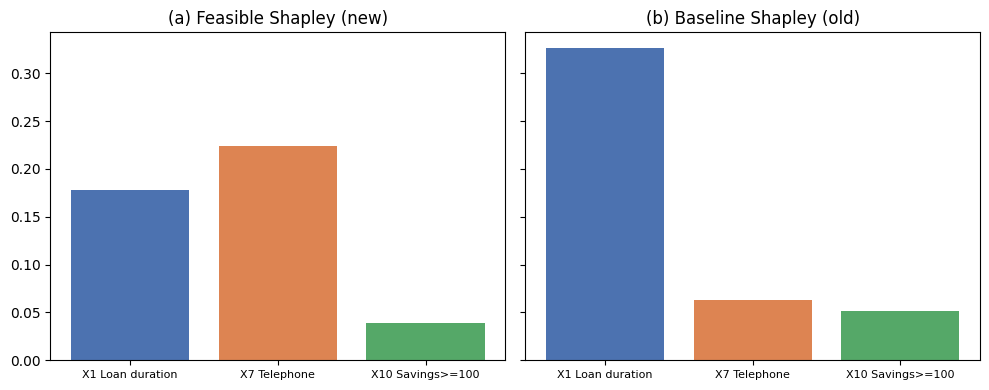

                                 新方法    老方法
LoanDuration                   0.178  0.326
HasTelephone                   0.224  0.063
SavingsAccountBalance_geq_100  0.039  0.051


In [6]:
import matplotlib.pyplot as plt
feasible = feasible_saved.iloc[0].values[changed]
names = ['X1 Loan duration', 'X7 Telephone', 'X10 Savings>=100']
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax[0].bar(names, feasible, color=['#4c72b0', '#dd8452', '#55a868']); ax[0].set_title('(a) Feasible Shapley (new)')
ax[1].bar(names, baseline, color=['#4c72b0', '#dd8452', '#55a868']); ax[1].set_title('(b) Baseline Shapley (old)')
for a in ax: a.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()
print(pd.DataFrame({'新方法': feasible, '老方法': baseline}, index=cols).round(3))

## A 部分小结
- 老方法：**贷款期限**功劳最大（约0.33），电话很小（约0.06）
- 新方法：**电话**和**贷款期限**差不多（约0.22 和 0.18）

为什么？因为“只把贷款期限从60个月改成10个月、其他不变”这类中间组合在真实数据里极少见，新方法把它们当作“不可能”，不让模型在那里瞎猜。这就是奶茶店里“只换包装、不上外卖”的情况。

---
# B 部分（选做）：亲手找出“不可能的点”
作者用一个神经网络估计“某种组合在现实中有多常见”，低于训练数据最罕见的5%，就判为不可能。这一步需要 TensorFlow，Colab 自带，但版本差异有时会出错。**如果报错，不影响 A 部分的结论。**

In [7]:
!pip -q install tf_keras
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import tensorflow as tf
import tf_keras as keras
from tf_keras.layers import Input, Dense
from tf_keras import regularizers

inp = Input(shape=(X_train.shape[1],))
h = inp
for _ in range(3):
    h = Dense(200, activation='relu', kernel_regularizer=regularizers.l1_l2(l1=1e-5, l2=1e-4))(h)
model_prob = keras.models.Model(inp, Dense(1)(h))
model_prob.load_weights('./german_prob_model_deep_1234.ckpt').expect_partial()

def pdf(Z):
    g = np.clip(1 / (1 + np.exp(-model_prob.predict(np.asarray(Z, dtype='float32'), verbose=0))), 0.01, 0.99)
    return (g / (1 - g) / 100).flatten()

threshold = np.percentile(pdf(X_train), 5)
print('“不可能”的门槛（训练数据密度的第5百分位）:', round(threshold, 4))

“不可能”的门槛（训练数据密度的第5百分位）: 0.0199


In [8]:
p0 = f_free(x0)[0]
def f_feasible(Z):
    # 可能的点：用模型预测；不可能的点：当作“没动”，保持原来的概率
    ok = pdf(Z) >= threshold
    return f_free(Z) * ok + p0 * (~ok)

outB = JointIndiShapley.finitechangesInd(x0, x1, f_feasible, Torder=10)
DX = outB[2]
dens = pdf(DX)
bad = DX.loc[dens < threshold, cols].copy()
bad['LoanDuration'] = bad['LoanDuration'] * raw_std['LoanDuration'] + raw_mean['LoanDuration']
bad['估计密度'] = dens[dens < threshold]
print('8个组合里，被判为不可能的有', len(bad), '个：')
display(bad.round(4))
mine = outB[-1].flatten()[changed]
print(pd.DataFrame({'我算的新方法': mine, '作者保存的新方法': feasible}, index=cols).round(3))

8个组合里，被判为不可能的有 2 个：


,LoanDuration,HasTelephone,SavingsAccountBalance_geq_100,估计密度
0,9.5971,0,0,0.0145
4,9.5971,0,1,0.0196


                               我算的新方法  作者保存的新方法
LoanDuration                    0.178     0.178
HasTelephone                    0.224     0.224
SavingsAccountBalance_geq_100   0.039     0.039
